# Error metrics AFTER data preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dhruvvvgg/bde-team7/blob/main/notebooks/error_metrics_after.ipynb)

The cleaned groundwater dataset the pipeline uses (2,759 quality-controlled wells). Ends with a before/after comparison.

Eight error metrics: RMSE, MSE, MAE, MAPE, R², NRMSE, MedAE and Bias (mean error), plus sMAPE.

## The metrics

| Metric | Full form | Formula (e = predicted − actual, y = actual) | Better when | Purpose |
|---|---|---|---|---|
| **RMSE** | Root Mean Square Error | `√( mean(e²) )` | lower | Square root of the average squared error; big misses weigh more. |
| **MSE** | Mean Squared Error | `mean(e²)` | lower | Average squared difference between actual and predicted values. |
| **MAE** | Mean Absolute Error | `mean(|e|)` | lower | Average absolute difference between actual and predicted values. |
| **MAPE** | Mean Absolute Percentage Error | `100 · mean(|e| / |y|), only where |y| ≥ 1 m` | lower | Prediction error as a percentage of the actual value. |
| **R2** | Coefficient of Determination | `1 − Σe² / Σ(y − ȳ)²` | higher | Share of the variation in actual values that the rule explains. |
| **NRMSE** | Normalized Root Mean Square Error | `RMSE / (max y − min y)` | lower | RMSE relative to the scale (range) of the target data. |
| **MedAE** | Median Absolute Error | `median(|e|)` | lower | Median absolute error; insensitive to extreme errors. |
| **Bias** | Mean Error (ME) | `mean(e)` | closer to 0 | Whether predictions systematically over- or under-estimate. |

## How these scores are produced

Data preprocessing does not make predictions, so there is nothing for RMSE, MAE or R² to score directly.
To get *before* and *after* error scores anyway, the **same fixed forecasting rules** are applied to the data
before and after cleaning, and scored on the **2018–2022 test period** (the readings the rules try to predict).
If cleaning makes the data more reliable and regular, the same rule scores better.

Each rule predicts a well's depth to groundwater (metres below ground) for a monitoring round using **only earlier rounds**:

| Rule | Prediction for a round |
|---|---|
| **same season last year** | the reading of the same season one year earlier (e.g. May 2019 → May 2018) |
| **seasonal mean of earlier years** | the mean of all earlier readings of that season, needing at least 5 (the pipeline's seasonal baseline) |
| **previous round** | the immediately previous round (a weak rule that ignores the seasonal cycle) |

These scores measure **data quality, not model skill**; the classifier results belong to the modeling stage.

## Reading notes

- **Units:** RMSE, MAE, MedAE and Bias are in metres of depth to groundwater; MSE is in m²; MAPE is a percentage; R² and NRMSE have no unit.
- **MAPE** divides by the actual value, which explodes for shallow water (0–1 m is common). It is therefore computed only
  where |actual| ≥ 1 m, and the number of readings used is reported (`MAPE_n`). **sMAPE** is a bounded alternative.
- **NRMSE** is RMSE divided by the range of the actual values (max − min); `NRMSE_mean` divides by the mean instead. Because the raw table
  contains impossible values (−97 m to 300 m), its range is huge, which makes its NRMSE look small without the forecasts being better.
- **R²** is measured against each dataset's own spread (variance). Datasets with extreme values have a large spread, so R² can look high
  there. Compare R² only between datasets with the same wells (the like-for-like comparison).
- **Bias** is the mean of (predicted − actual). Positive means the rule predicts water deeper than what was measured. The rules learn from earlier
  years, so a bias appears when the test period differs from them; section 1 reports the measured difference in mean depth.
- The number of scored readings `n` differs between rules (a rule needs its own earlier readings to exist) and between datasets.

## 0. Setup

In [1]:
import os, subprocess, sys, warnings
from pathlib import Path

REPO_URL = "https://github.com/dhruvvvgg/bde-team7.git"      # if the repository is private, put an access token in the URL (never save it in the notebook)

# Use the current folder if it is the repository; otherwise clone it (e.g. in Colab).
if Path("src/gwstress").exists():
    ROOT = Path.cwd()
elif Path("../src/gwstress").exists():          # opened from notebooks/
    ROOT = Path("..").resolve()
else:
    if not Path("bde-team7").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "bde-team7"], check=True)
    ROOT = Path("bde-team7").resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="DataFrame is highly fragmented")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from gwstress import error_metrics as em

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 60)
BEFORE, AFTER = "#eb6834", "#2a78d6"            # entity colours: orange = before cleaning, blue = after
INK2, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "legend.frameon": False})
SHORT = {"same season last year": "same season\nlast year", "seasonal mean of earlier years": "seasonal mean\nof earlier years",
         "previous round": "previous\nround"}
METRICS = [("RMSE", "m"), ("MSE", "m²"), ("MAE", "m"), ("MAPE", "%"), ("R2", ""), ("NRMSE", "fraction of range"),
           ("MedAE", "m"), ("Bias", "m")]
ROUND_LABELS = [f"{m}-{y % 100:02d}" for y in range(2000, 2023) for m in em.SEASONS]
OUT = ROOT / "reports" / "tables"
OUT.mkdir(parents=True, exist_ok=True)
print("repository:", ROOT)

repository: /home/user/bde-team7


## 1. The data (after cleaning)

In [2]:
ds = em.load_cleaned()
COLOR = AFTER
display(ds.describe().rename(columns={"value": ds.name}).round(3))

,"cleaned, 2,759 wells"
wells,2759.000
readings,219258.000
missing % of cells,13.620
min (m),0.000
max (m),66.900
mean (m),5.760
median (m),4.600
std (m),4.856
negative readings,0.000
zero readings,11.000


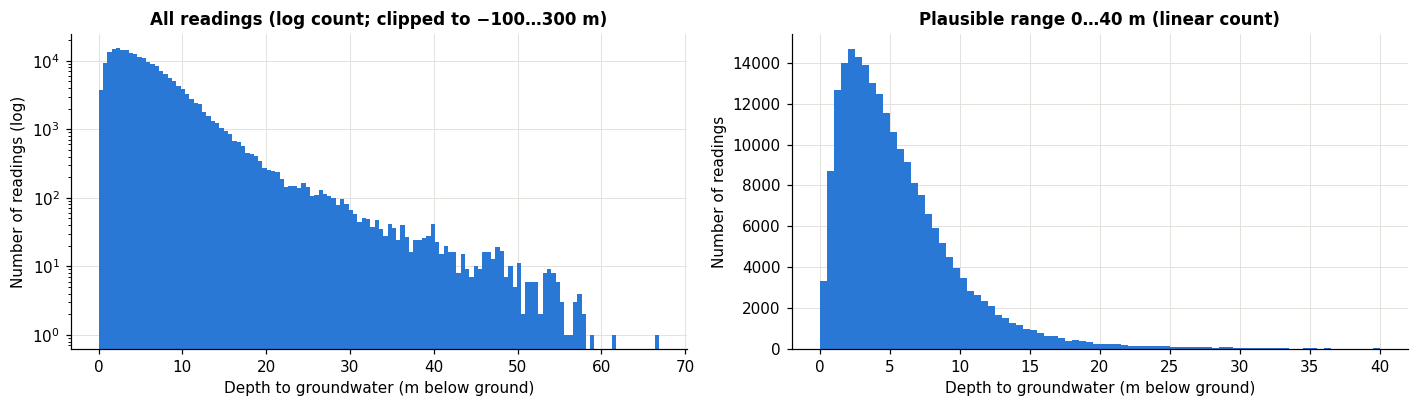

**cleaned, 2,759 wells**: 2,759 wells, 219,258 readings; range 0 to 66.9 m; **0 negative** and **0 readings above 100 m** (physically implausible).

Mean depth in the earlier years (2000–2017): **5.86 m**; in the test period (2018–2022): **5.35 m** (-0.51 m). Rules that learn from earlier years inherit this shift as bias.

In [3]:
v = ds.values[np.isfinite(ds.values)]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(np.clip(v, -100, 300), bins=130, color=COLOR)
ax[0].set_yscale("log")
ax[0].set_title("All readings (log count; clipped to −100…300 m)")
ax[0].set_xlabel("Depth to groundwater (m below ground)")
ax[0].set_ylabel("Number of readings (log)")
ax[1].hist(v[(v >= 0) & (v <= 40)], bins=80, color=COLOR)
ax[1].set_title("Plausible range 0…40 m (linear count)")
ax[1].set_xlabel("Depth to groundwater (m below ground)")
ax[1].set_ylabel("Number of readings")
plt.tight_layout(); plt.show()
n_bad = int(((v < 0) | (v > 100)).sum())
display(Markdown(f"**{ds.name}**: {len(ds.values):,} wells, {v.size:,} readings; "
                 f"range {v.min():g} to {v.max():g} m; **{int((v < 0).sum()):,} negative** and "
                 f"**{int((v > 100).sum()):,} readings above 100 m** (physically implausible)."))
early = np.nanmean(ds.values[:, :em.TEST_FIRST_COL]); late = np.nanmean(ds.values[:, em.TEST_FIRST_COL:])
display(Markdown(f"Mean depth in the earlier years (2000–2017): **{early:.2f} m**; in the test period (2018–2022): **{late:.2f} m** "
                 f"({late - early:+.2f} m). Rules that learn from earlier years inherit this shift as bias."))

## 2. The forecasting rules in action

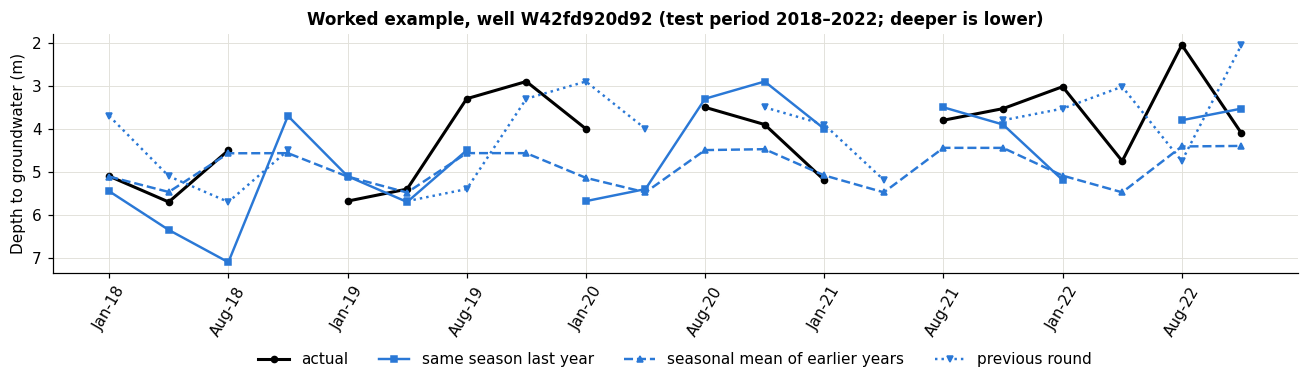

In [4]:
preds = em.predictions(ds.values)
wid = np.flatnonzero(ds.well_ids == "W42fd920d92")
i = int(wid[0]) if len(wid) else int(np.argmax(np.isfinite(ds.values[:, em.TEST_FIRST_COL:]).sum(axis=1)))
cols = np.arange(em.TEST_FIRST_COL, em.N_ROUNDS)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cols, ds.values[i, cols], color="black", lw=2, marker="o", ms=4, label="actual")
for (rule, p), mk, ls in zip(preds.items(), ["s", "^", "v"], ["-", "--", ":"]):
    ax.plot(cols, p[i, cols], color=COLOR, lw=1.6, ls=ls, marker=mk, ms=4, label=rule)
ax.set_xticks(cols[::2], [ROUND_LABELS[c] for c in cols[::2]], rotation=60)
ax.set_ylabel("Depth to groundwater (m)")
ax.invert_yaxis()
ax.set_title(f"Worked example, well {ds.well_ids[i]} (test period 2018–2022; deeper is lower)")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout(); plt.show()

## 3. All eight metrics

In [5]:
tbl = em.metric_table(ds)
show = tbl.set_index("rule")[["n", "RMSE", "MSE", "MAE", "MAPE", "R2", "NRMSE", "MedAE", "Bias"]]
show = show.rename(columns={"RMSE": "RMSE (m)", "MSE": "MSE (m²)", "MAE": "MAE (m)", "MAPE": "MAPE (%)",
                            "NRMSE": "NRMSE (range)", "MedAE": "MedAE (m)", "Bias": "Bias / ME (m)"})
display(Markdown(f"### All eight metrics: {ds.name}, test period 2018–2022"))
display(show.round(3))
display(Markdown("Extra scores: NRMSE relative to the mean, sMAPE, and how many readings MAPE could use:"))
display(tbl.set_index("rule")[["NRMSE_mean", "sMAPE", "MAPE_n"]].round(3))

### All eight metrics: cleaned, 2,759 wells, test period 2018–2022

,n,RMSE (m),MSE (m²),MAE (m),MAPE (%),R2,NRMSE (range),MedAE (m),Bias / ME (m)
rule,,,,,,,,,
same season last year,38723,2.554,6.525,1.491,36.843,0.712,0.038,0.830,0.209
seasonal mean of earlier years,44133,2.449,5.996,1.553,38.858,0.741,0.037,0.964,0.346
previous round,34900,3.081,9.495,1.996,49.784,0.596,0.046,1.240,-0.178


Extra scores: NRMSE relative to the mean, sMAPE, and how many readings MAPE could use:

,NRMSE_mean,sMAPE,MAPE_n
rule,,,
same season last year,0.479,33.882,36117
seasonal mean of earlier years,0.457,33.868,41129
previous round,0.551,44.863,32992


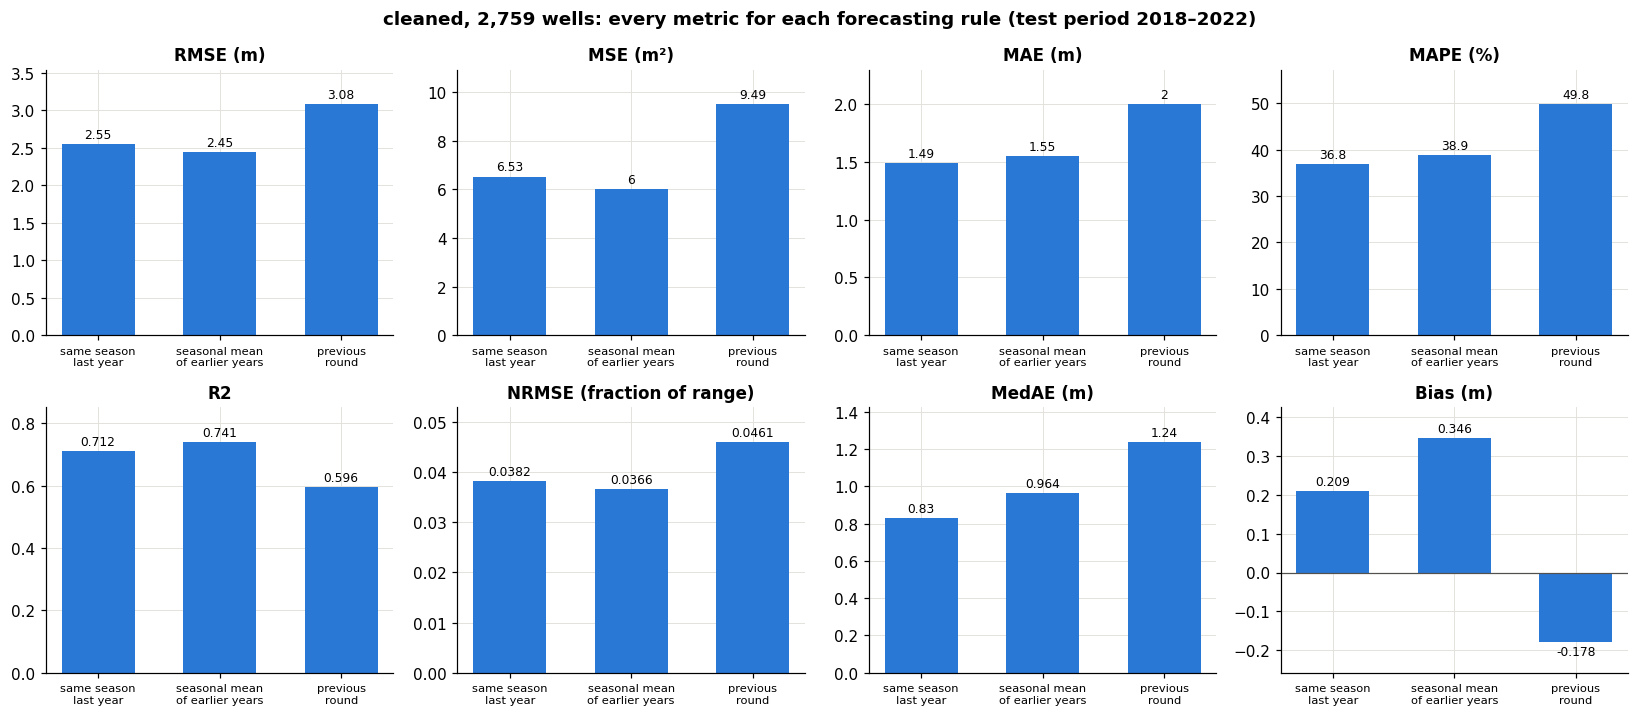

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for ax, (m, unit) in zip(axes.ravel(), METRICS):
    vals = tbl[m].to_numpy()
    bars = ax.bar(range(3), vals, color=COLOR, width=0.6)
    ax.bar_label(bars, fmt="%.3g", fontsize=8, padding=2)
    ax.set_xticks(range(3), [SHORT[r] for r in tbl.rule], fontsize=7.5)
    ax.set_title(f"{m} ({unit})" if unit else m)
    if m == "Bias":
        ax.axhline(0, color=INK2, lw=0.8)
    ax.margins(y=0.15)
fig.suptitle(f"{ds.name}: every metric for each forecasting rule (test period 2018–2022)", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Where the errors are

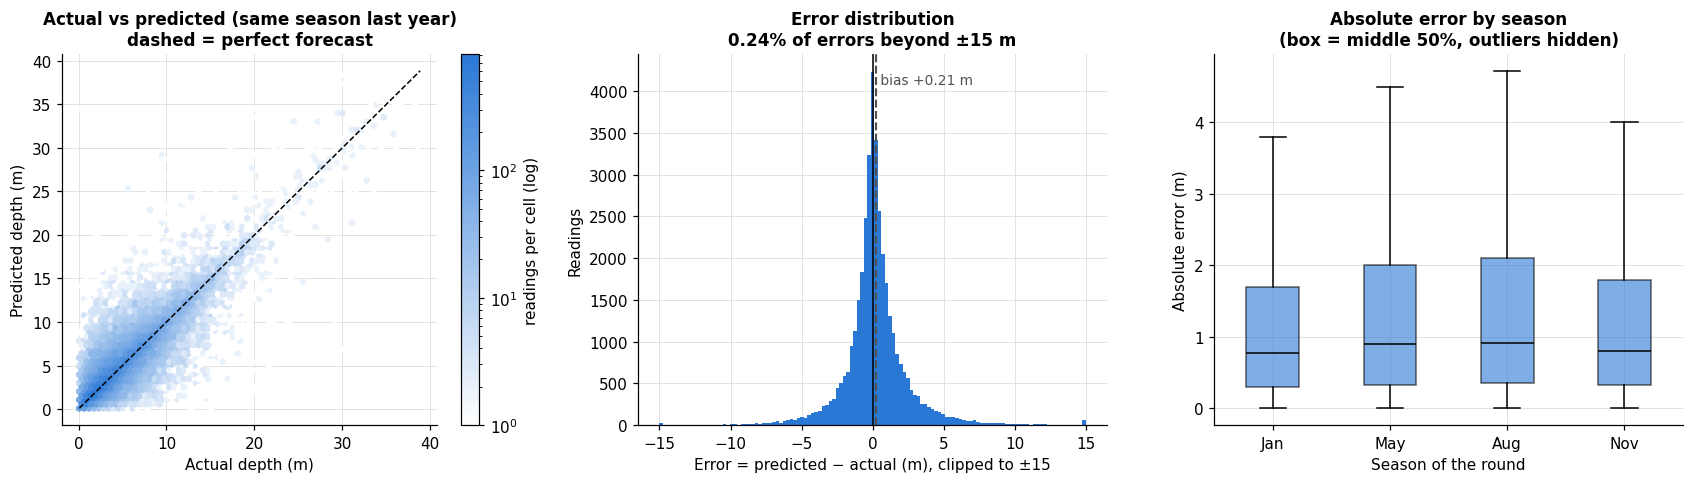

In [7]:
rule = em.PRIMARY_RULE
y, q, pcols, prows = em.test_pairs(ds, rule)
e = q - y
lo, hi = np.percentile(y, [0.2, 99.8])
cmap = LinearSegmentedColormap.from_list("c", ["#ffffff", COLOR])
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.5))
hb = ax[0].hexbin(y, q, gridsize=70, bins="log", cmap=cmap, mincnt=1, extent=(lo, hi, lo, hi))
ax[0].plot([lo, hi], [lo, hi], color="black", lw=1, ls="--")
ax[0].set_xlabel("Actual depth (m)"); ax[0].set_ylabel("Predicted depth (m)")
ax[0].set_title(f"Actual vs predicted ({rule})\ndashed = perfect forecast")
fig.colorbar(hb, ax=ax[0], label="readings per cell (log)")
ax[1].hist(np.clip(e, -15, 15), bins=121, color=COLOR)
ax[1].axvline(0, color="black", lw=1); ax[1].axvline(e.mean(), color=INK2, lw=1.4, ls="--")
ax[1].text(e.mean(), ax[1].get_ylim()[1] * 0.92, f" bias {e.mean():+.2f} m", color=INK2, fontsize=9)
ax[1].set_xlabel("Error = predicted − actual (m), clipped to ±15"); ax[1].set_ylabel("Readings")
ax[1].set_title(f"Error distribution\n{(np.abs(e) > 15).mean() * 100:.2f}% of errors beyond ±15 m")
season = np.array(em.SEASONS)[pcols % 4]
ax[2].boxplot([np.abs(e)[season == s] for s in em.SEASONS], showfliers=False, patch_artist=True,
              boxprops=dict(facecolor=COLOR, alpha=0.6), medianprops=dict(color="black"))
ax[2].set_xticks(range(1, 5), em.SEASONS)
ax[2].set_ylabel("Absolute error (m)"); ax[2].set_xlabel("Season of the round")
ax[2].set_title("Absolute error by season\n(box = middle 50%, outliers hidden)")
plt.tight_layout(); plt.show()

## 5. Breakdown by season, year and state

### By season (same season last year)

,wells,n,RMSE,MSE,MAE,MAPE,R2,NRMSE,MedAE,Bias
season,,,,,,,,,,
Jan,2758,12912,2.525,6.377,1.417,30.956,0.695,0.046,0.78,0.304
May,2098,4058,2.546,6.483,1.549,22.853,0.773,0.044,0.90,-0.096
Aug,2747,10539,2.772,7.683,1.637,50.195,0.654,0.041,0.92,0.271
Nov,2753,11214,2.371,5.622,1.417,37.874,0.684,0.045,0.80,0.152


RMSE (m) by season for every rule:

,same season last year,seasonal mean of earlier years,previous round
season,,,
Jan,2.525,2.409,2.114
May,2.546,2.656,3.089
Aug,2.772,2.530,5.053
Nov,2.371,2.297,2.492


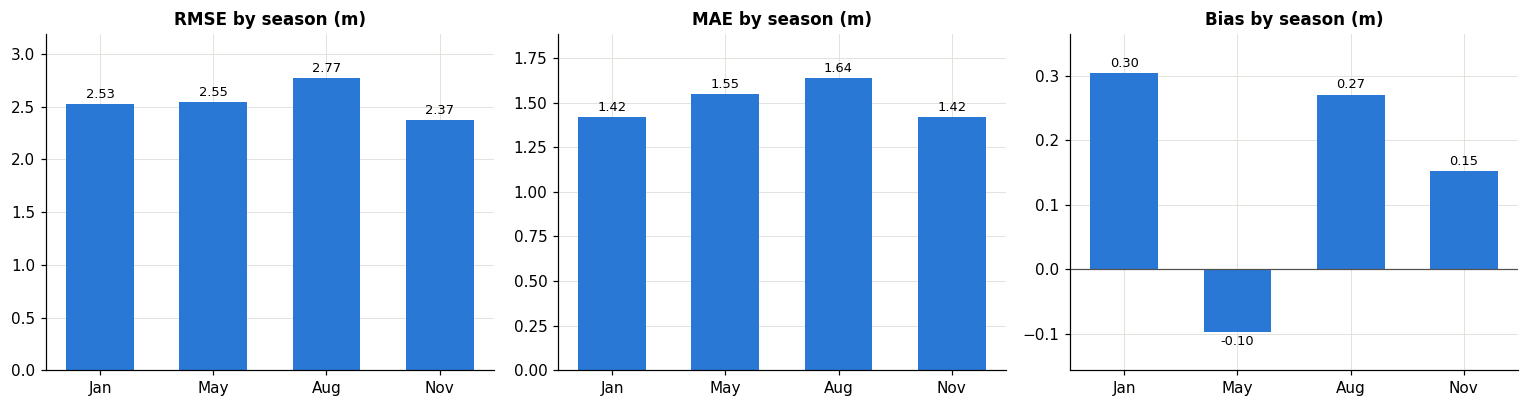

In [8]:
bs = em.breakdown(ds, em.PRIMARY_RULE, "season")
display(Markdown(f"### By season ({em.PRIMARY_RULE})"))
display(bs[["season", "wells", "n", "RMSE", "MSE", "MAE", "MAPE", "R2", "NRMSE", "MedAE", "Bias"]].round(3).set_index("season"))
piv = pd.DataFrame({r: em.breakdown(ds, r, "season").set_index("season")["RMSE"] for r in em.RULES})
display(Markdown("RMSE (m) by season for every rule:"))
display(piv.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, m in zip(ax, ["RMSE", "MAE", "Bias"]):
    b = a.bar(bs.season.astype(str), bs[m], color=COLOR, width=0.6)
    a.bar_label(b, fmt="%.2f", fontsize=8.5, padding=2)
    a.set_title(f"{m} by season (m)")
    if m == "Bias":
        a.axhline(0, color=INK2, lw=0.8)
    a.margins(y=0.15)
plt.tight_layout(); plt.show()

### By year (same season last year)

,wells,n,RMSE,MAE,R2,MedAE,Bias
year,,,,,,,
2018,2758,8893,2.555,1.503,0.742,0.82,0.113
2019,2757,8784,2.656,1.582,0.750,0.90,0.071
2020,2753,6745,2.902,1.639,0.576,0.90,0.612
2021,2759,6792,2.416,1.394,0.697,0.78,-0.065
2022,2754,7509,2.196,1.325,0.693,0.75,0.369


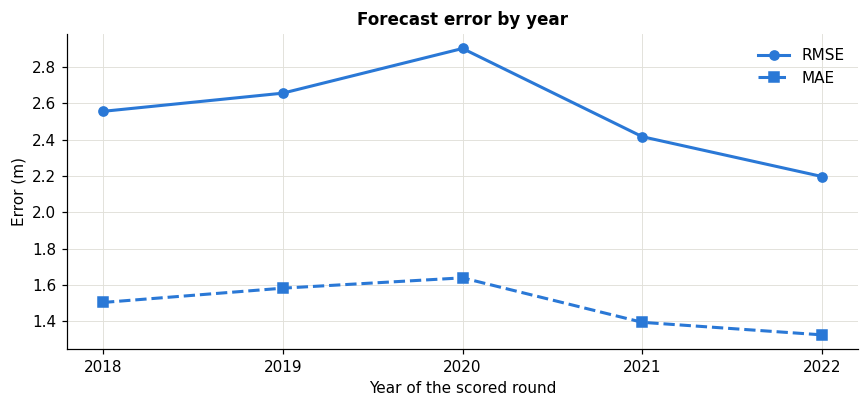

In [9]:
by = em.breakdown(ds, em.PRIMARY_RULE, "year")
display(Markdown(f"### By year ({em.PRIMARY_RULE})"))
display(by[["year", "wells", "n", "RMSE", "MAE", "R2", "MedAE", "Bias"]].round(3).set_index("year"))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by.year, by.RMSE, color=COLOR, lw=2, marker="o", label="RMSE")
ax.plot(by.year, by.MAE, color=COLOR, lw=2, ls="--", marker="s", label="MAE")
ax.set_xticks(by.year); ax.set_ylabel("Error (m)"); ax.set_xlabel("Year of the scored round")
ax.set_title("Forecast error by year"); ax.legend()
plt.tight_layout(); plt.show()

### By state (same season last year), sorted by RMSE

,wells,n,RMSE,MAE,R2,MedAE,Bias
state,,,,,,,
Tamil Nadu,175,2576,4.298,2.490,0.548,1.450,0.864
Gujarat,271,3643,3.448,2.150,0.744,1.210,0.160
Telangana,82,1174,3.219,1.804,0.736,0.870,0.245
Madhya Pradesh,501,8124,2.767,1.789,0.595,1.090,0.267
Karnataka,217,3034,2.686,1.519,0.473,0.930,0.267
Andhra Pradesh,169,2458,2.450,1.375,0.683,0.730,0.214
West Bengal,68,872,2.097,1.280,0.553,0.735,0.028
Chhattisgarh,130,1879,2.073,1.244,0.473,0.740,0.082
Jharkhand,35,418,2.057,1.391,0.367,0.855,-0.293


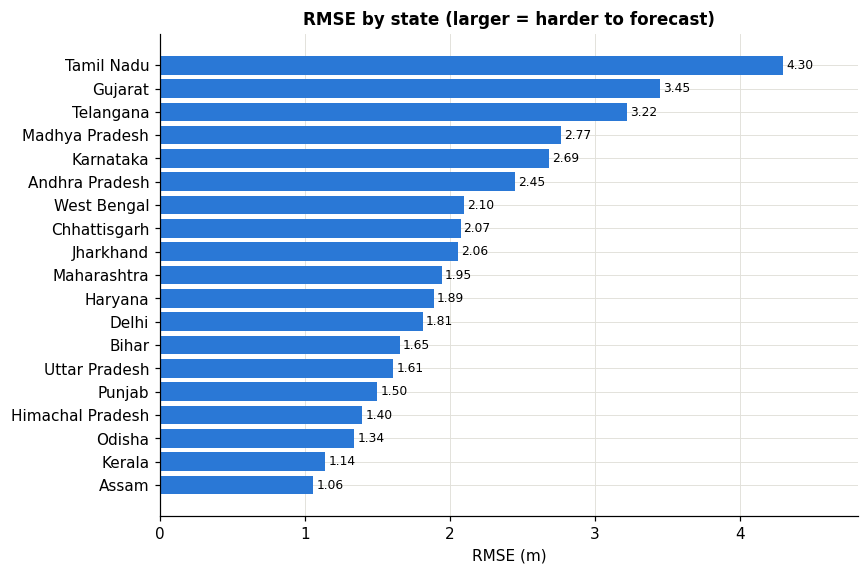

In [10]:
st = em.breakdown(ds, em.PRIMARY_RULE, "state").sort_values("RMSE", ascending=False)
display(Markdown(f"### By state ({em.PRIMARY_RULE}), sorted by RMSE"))
display(st[["state", "wells", "n", "RMSE", "MAE", "R2", "MedAE", "Bias"]].round(3).set_index("state"))
fig, ax = plt.subplots(figsize=(8, max(3.5, 0.28 * len(st))))
b = ax.barh(st.state[::-1], st.RMSE[::-1], color=COLOR)
ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
ax.set_xlabel("RMSE (m)"); ax.set_title("RMSE by state (larger = harder to forecast)")
ax.margins(x=0.12)
plt.tight_layout(); plt.show()

## 6. Before vs after comparison

In [11]:
raw_same = em.load_raw_same_wells()
raw_all = em.load_raw_all()
t_after, t_same, t_all = tbl, em.metric_table(raw_same), em.metric_table(raw_all)
blanked = int((np.isfinite(raw_same.values) & ~np.isfinite(ds.values)).sum())
changed = int((np.isfinite(raw_same.values) & np.isfinite(ds.values) & (np.abs(raw_same.values - ds.values) > 1e-9)).sum())
display(Markdown(f"Cleaning blanked **{blanked:,}** raw readings of these wells (the dataset authors' per-well 3-sigma outlier rule) "
                 f"and changed **{changed}** other values. Everything else is identical."))

saved = OUT / "error_metrics_before.csv"
if saved.exists():
    prev = pd.read_csv(saved)
    chk = prev.merge(pd.concat([t_all, t_same]), on=["data", "rule"], suffixes=("_saved", "_now"))
    assert len(chk) == len(prev) and all(np.allclose(chk[f"{c}_saved"], chk[f"{c}_now"], equal_nan=True)
                                         for c in ["n", "RMSE", "MAE", "MAPE", "R2", "MedAE", "Bias"])
    print("Cross-check passed: the 'before' numbers equal those saved by error_metrics_before.ipynb")
else:
    print("(error_metrics_before.csv not found; run the before notebook first to enable the cross-check)")

Cleaning blanked **1,217** raw readings of these wells (the dataset authors' per-well 3-sigma outlier rule) and changed **0** other values. Everything else is identical.

Cross-check passed: the 'before' numbers equal those saved by error_metrics_before.ipynb


In [12]:
BETTER = {"R2": "higher", "Bias": "closer to 0"}

def side_by_side(before, after, rule):
    b = before.set_index("rule").loc[rule]; a = after.set_index("rule").loc[rule]
    rows = []
    for m, unit in METRICS:
        verdict = (a[m] > b[m]) if m == "R2" else (abs(a[m]) < abs(b[m])) if m == "Bias" else (a[m] < b[m])
        rows.append({"metric": m + (f" ({unit})" if unit else ""), "before": b[m], "after": a[m], "change": a[m] - b[m],
                     "improvement": em.improvement(b[m], a[m], m), "better when": BETTER.get(m, "lower"),
                     "verdict": "better" if verdict else "worse"})
    out = pd.DataFrame(rows).set_index("metric")
    out["improvement"] = out["improvement"].round(2)
    return out

display(Markdown("## A. Like-for-like: the same 2,759 wells, raw values (before) vs cleaned values (after)"))
display(Markdown("`improvement` is the percentage reduction in error (positive = after is better); for R² it is the absolute change; for Bias it is the reduction in |bias|."))
for rule in em.RULES:
    display(Markdown(f"**Rule: {rule}**   (before n = {int(t_same.set_index('rule').loc[rule, 'n']):,}, after n = {int(t_after.set_index('rule').loc[rule, 'n']):,})"))
    display(side_by_side(t_same, t_after, rule).round(4))

## A. Like-for-like: the same 2,759 wells, raw values (before) vs cleaned values (after)

`improvement` is the percentage reduction in error (positive = after is better); for R² it is the absolute change; for Bias it is the reduction in |bias|.

**Rule: same season last year**   (before n = 39,110, after n = 38,723)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),2.6838,2.5544,-0.1294,4.82,lower,better
MSE (m²),7.2029,6.5251,-0.6778,9.41,lower,better
MAE (m),1.5420,1.4908,-0.0512,3.32,lower,better
MAPE (%),37.7787,36.8426,-0.9360,2.48,lower,better
R2,0.6895,0.7123,0.0228,0.02,higher,better
NRMSE (fraction of range),0.0401,0.0382,-0.0019,4.82,lower,better
MedAE (m),0.8500,0.8300,-0.0200,2.35,lower,better
Bias (m),0.2102,0.2090,-0.0011,0.53,closer to 0,better


**Rule: seasonal mean of earlier years**   (before n = 44,379, after n = 44,133)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),2.5346,2.4486,-0.0860,3.39,lower,better
MSE (m²),6.4240,5.9956,-0.4285,6.67,lower,better
MAE (m),1.5955,1.5526,-0.0429,2.69,lower,better
MAPE (%),39.7391,38.8581,-0.8810,2.22,lower,better
R2,0.7273,0.7408,0.0135,0.01,higher,better
NRMSE (fraction of range),0.0379,0.0366,-0.0013,3.39,lower,better
MedAE (m),0.9889,0.9642,-0.0247,2.50,lower,better
Bias (m),0.3504,0.3455,-0.0049,1.39,closer to 0,better


**Rule: previous round**   (before n = 35,288, after n = 34,900)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),3.2091,3.0814,-0.1277,3.98,lower,better
MSE (m²),10.2981,9.4949,-0.8032,7.80,lower,better
MAE (m),2.0528,1.9964,-0.0564,2.75,lower,better
MAPE (%),50.8502,49.7838,-1.0664,2.10,lower,better
R2,0.5717,0.5960,0.0243,0.02,higher,better
NRMSE (fraction of range),0.0480,0.0461,-0.0019,3.98,lower,better
MedAE (m),1.2600,1.2400,-0.0200,1.59,lower,better
Bias (m),-0.1790,-0.1784,0.0006,0.32,closer to 0,better


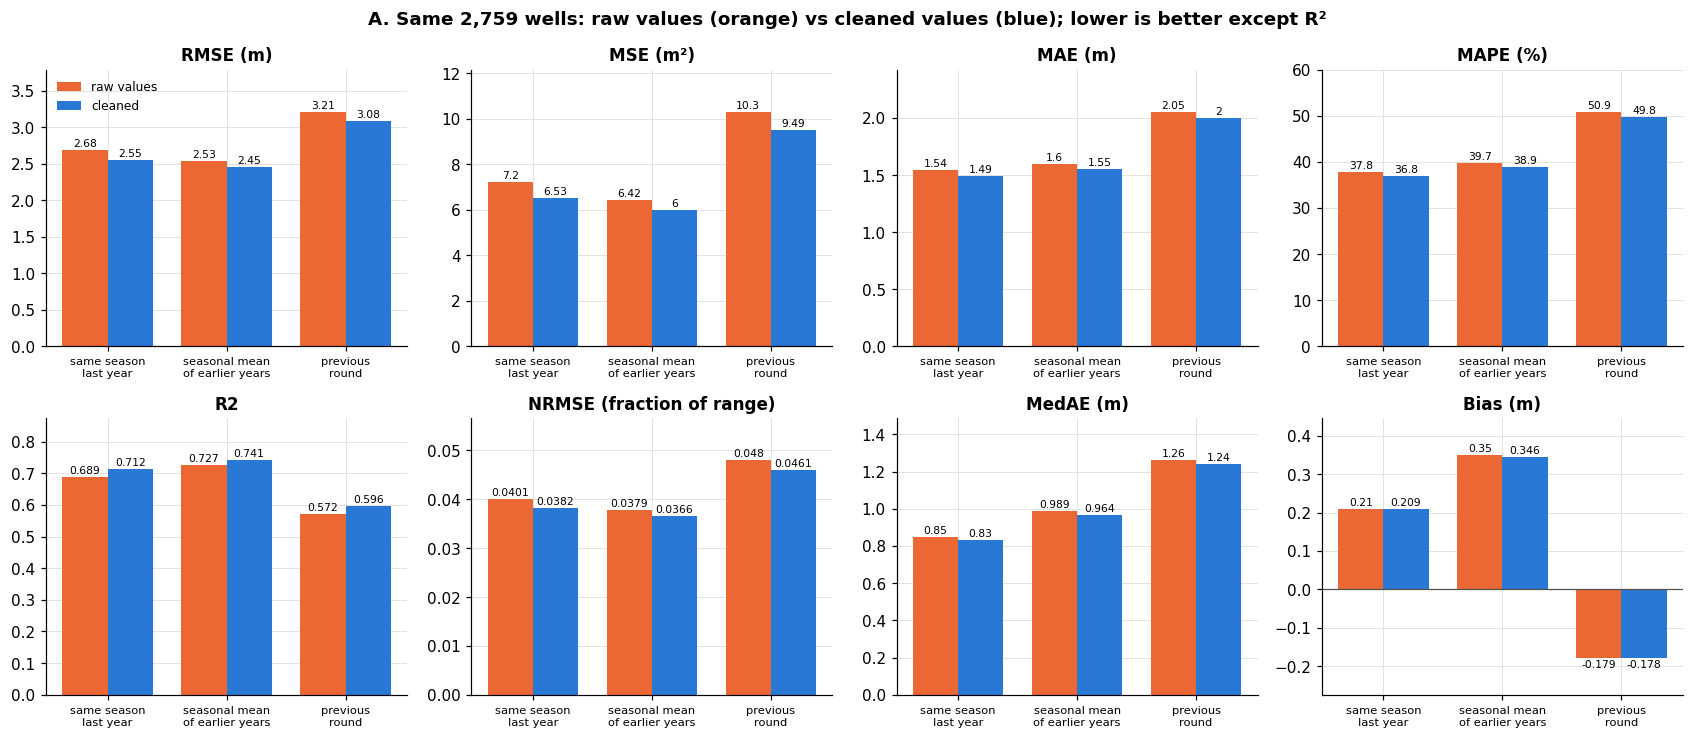

In [13]:
def compare_panels(tb, ta, title, lb="before", la="after"):
    fig, axes = plt.subplots(2, 4, figsize=(15.5, 6.8))
    x = np.arange(3); w = 0.38
    for ax, (m, unit) in zip(axes.ravel(), METRICS):
        b1 = ax.bar(x - w / 2, tb[m], w, color=BEFORE, label=lb)
        b2 = ax.bar(x + w / 2, ta[m], w, color=AFTER, label=la)
        ax.bar_label(b1, fmt="%.3g", fontsize=7, padding=1); ax.bar_label(b2, fmt="%.3g", fontsize=7, padding=1)
        ax.set_xticks(x, [SHORT[r] for r in tb.rule], fontsize=7.5)
        ax.set_title(f"{m} ({unit})" if unit else m)
        if m == "Bias":
            ax.axhline(0, color=INK2, lw=0.8)
        ax.margins(y=0.18)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout(); plt.show()

compare_panels(t_same, t_after, "A. Same 2,759 wells: raw values (orange) vs cleaned values (blue); lower is better except R²", "raw values", "cleaned")

### Season-by-season, same 2,759 wells (same season last year)

RMSE           MAE            R2          Bias       
       before  after before  after before  after before  after
season                                                        
Jan     2.631  2.525  1.456  1.417  0.675  0.695  0.303  0.304
May     2.881  2.546  1.683  1.549  0.730  0.773 -0.103 -0.096
Aug     2.889  2.772  1.687  1.637  0.626  0.654  0.281  0.271
Nov     2.457  2.371  1.452  1.417  0.664  0.684  0.153  0.152

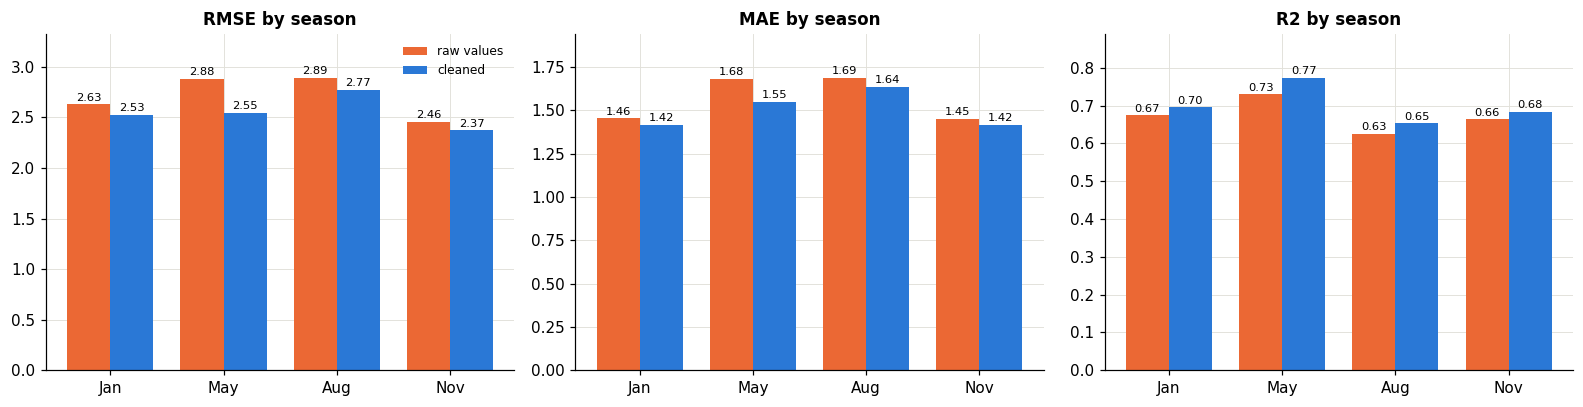

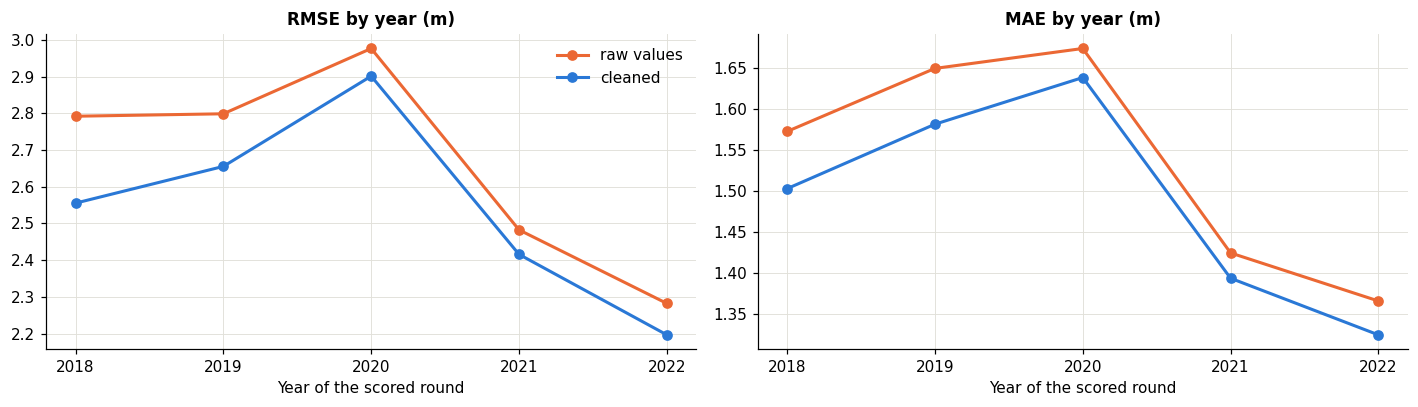

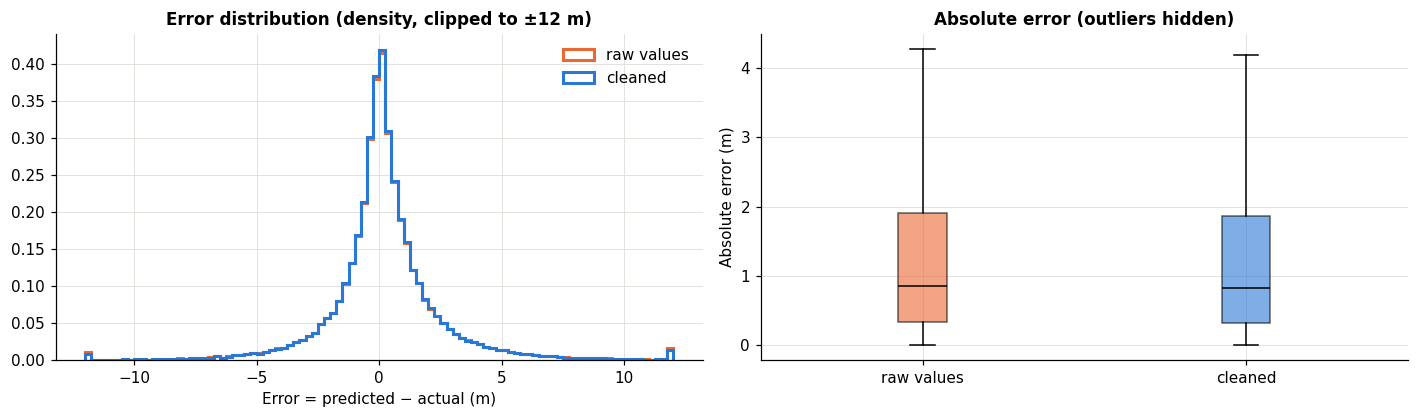

In [14]:
rule = em.PRIMARY_RULE
bsb = em.breakdown(raw_same, rule, "season"); bsa = em.breakdown(ds, rule, "season")
display(Markdown(f"### Season-by-season, same 2,759 wells ({rule})"))
sea = pd.DataFrame({("RMSE", "before"): bsb.RMSE.values, ("RMSE", "after"): bsa.RMSE.values,
                    ("MAE", "before"): bsb.MAE.values, ("MAE", "after"): bsa.MAE.values,
                    ("R2", "before"): bsb.R2.values, ("R2", "after"): bsa.R2.values,
                    ("Bias", "before"): bsb.Bias.values, ("Bias", "after"): bsa.Bias.values}, index=bsa.season.astype(str))
display(sea.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14.5, 3.8))
x = np.arange(4); w = 0.38
for a, m in zip(ax, ["RMSE", "MAE", "R2"]):
    b1 = a.bar(x - w / 2, bsb[m], w, color=BEFORE, label="raw values"); b2 = a.bar(x + w / 2, bsa[m], w, color=AFTER, label="cleaned")
    a.bar_label(b1, fmt="%.2f", fontsize=7.5, padding=1); a.bar_label(b2, fmt="%.2f", fontsize=7.5, padding=1)
    a.set_xticks(x, em.SEASONS); a.set_title(f"{m} by season"); a.margins(y=0.15)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

yb = em.breakdown(raw_same, rule, "year"); ya = em.breakdown(ds, rule, "year")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, m in zip(ax, ["RMSE", "MAE"]):
    a.plot(yb.year, yb[m], color=BEFORE, lw=2, marker="o", label="raw values")
    a.plot(ya.year, ya[m], color=AFTER, lw=2, marker="o", label="cleaned")
    a.set_xticks(ya.year); a.set_title(f"{m} by year (m)"); a.set_xlabel("Year of the scored round")
ax[0].legend()
plt.tight_layout(); plt.show()

yb_, qb_, _, _ = em.test_pairs(raw_same, rule); ya_, qa_, _, _ = em.test_pairs(ds, rule)
eb, ea = qb_ - yb_, qa_ - ya_
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
bins = np.linspace(-12, 12, 97)
ax[0].hist(np.clip(eb, -12, 12), bins=bins, histtype="step", lw=2, color=BEFORE, density=True, label="raw values")
ax[0].hist(np.clip(ea, -12, 12), bins=bins, histtype="step", lw=2, color=AFTER, density=True, label="cleaned")
ax[0].set_title("Error distribution (density, clipped to ±12 m)"); ax[0].set_xlabel("Error = predicted − actual (m)"); ax[0].legend()
ax[1].boxplot([np.abs(eb), np.abs(ea)], showfliers=False, patch_artist=True,
              boxprops=dict(alpha=0.6), medianprops=dict(color="black"))
ax[1].set_xticks([1, 2], ["raw values", "cleaned"])
for patch, c in zip(ax[1].patches, [BEFORE, AFTER]):
    patch.set_facecolor(c)
ax[1].set_ylabel("Absolute error (m)"); ax[1].set_title("Absolute error (outliers hidden)")
plt.tight_layout(); plt.show()

## B. Whole raw table (all well rows) vs the cleaned 2,759 wells

Different wells and a very different spread of values, so R², NRMSE and MAPE are **not** comparable here (see the reading notes). Errors fall sharply mainly because of which wells were kept (section C splits the gain into well selection and value cleaning).

**Rule: same season last year**   (before n = 218,554, after n = 38,723)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),4.5554,2.5544,-2.0010,43.93,lower,better
MSE (m²),20.7515,6.5251,-14.2264,68.56,lower,better
MAE (m),1.9755,1.4908,-0.4847,24.54,lower,better
MAPE (%),37.8231,36.8426,-0.9804,2.59,lower,better
R2,0.8459,0.7123,-0.1337,-0.13,higher,worse
NRMSE (fraction of range),0.0151,0.0382,0.0231,-152.71,lower,worse
MedAE (m),0.9200,0.8300,-0.0900,9.78,lower,better
Bias (m),0.1927,0.2090,0.0164,-8.49,closer to 0,worse


**Rule: seasonal mean of earlier years**   (before n = 214,872, after n = 44,133)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),5.0559,2.4486,-2.6073,51.57,lower,better
MSE (m²),25.5617,5.9956,-19.5662,76.54,lower,better
MAE (m),2.3565,1.5526,-0.8039,34.11,lower,better
MAPE (%),42.1550,38.8581,-3.2970,7.82,lower,better
R2,0.7841,0.7408,-0.0433,-0.04,higher,worse
NRMSE (fraction of range),0.0168,0.0366,0.0198,-118.26,lower,worse
MedAE (m),1.1792,0.9642,-0.2150,18.23,lower,better
Bias (m),0.2144,0.3455,0.1311,-61.13,closer to 0,worse


**Rule: previous round**   (before n = 192,359, after n = 34,900)

,before,after,change,improvement,better when,verdict
metric,,,,,,
RMSE (m),4.1138,3.0814,-1.0324,25.10,lower,better
MSE (m²),16.9232,9.4949,-7.4283,43.89,lower,better
MAE (m),2.1974,1.9964,-0.2010,9.15,lower,better
MAPE (%),46.8769,49.7838,2.9069,-6.20,lower,worse
R2,0.8511,0.5960,-0.2551,-0.26,higher,worse
NRMSE (fraction of range),0.0201,0.0461,0.0259,-128.85,lower,worse
MedAE (m),1.2200,1.2400,0.0200,-1.64,lower,worse
Bias (m),-0.1777,-0.1784,-0.0007,-0.37,closer to 0,worse


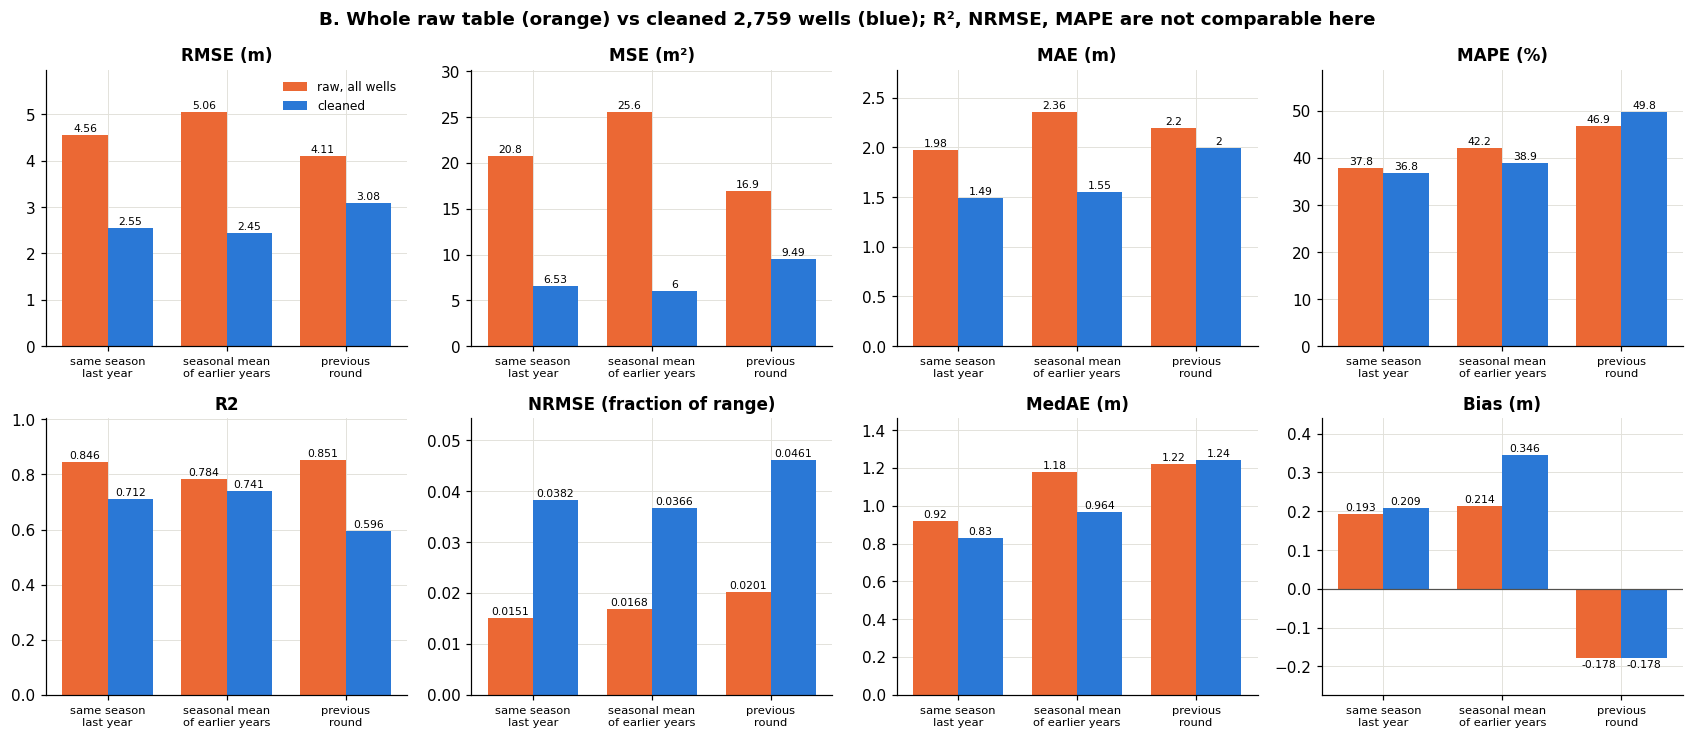

In [15]:
display(Markdown("## B. Whole raw table (all well rows) vs the cleaned 2,759 wells"))
display(Markdown("Different wells and a very different spread of values, so R², NRMSE and MAPE are **not** comparable here (see the reading notes). "
                 "Errors fall sharply mainly because of which wells were kept (section C splits the gain into well selection and value cleaning)."))
for rule in em.RULES:
    display(Markdown(f"**Rule: {rule}**   (before n = {int(t_all.set_index('rule').loc[rule, 'n']):,}, after n = {int(t_after.set_index('rule').loc[rule, 'n']):,})"))
    display(side_by_side(t_all, t_after, rule).round(4))
compare_panels(t_all, t_after, "B. Whole raw table (orange) vs cleaned 2,759 wells (blue); R², NRMSE, MAPE are not comparable here", "raw, all wells", "cleaned")

## C. Where does the improvement come from?

### Rule: same season last year

Step 1 → 2 changes **which wells** are scored: the authors kept only wells without negative values, with at least 2 readings in every year and no stuck repeated values. Step 2 → 3 changes **values** only: outlier readings were blanked.

,wells,n,RMSE,MAE,MedAE,R2
stage,,,,,,
"1. raw table, all wells",32299,218554,4.555,1.975,0.92,0.846
"2. raw values, same 2,759 wells",2759,39110,2.684,1.542,0.85,0.689
"3. cleaned, 2,759 wells",2759,38723,2.554,1.491,0.83,0.712


Share of the total reduction going from step 1 to step 3: RMSE **93.5% from well selection** and 6.5% from blanking readings; MAE 89.4% / 10.6%. (R² is not comparable between stage 1 and the others; see the reading notes.)

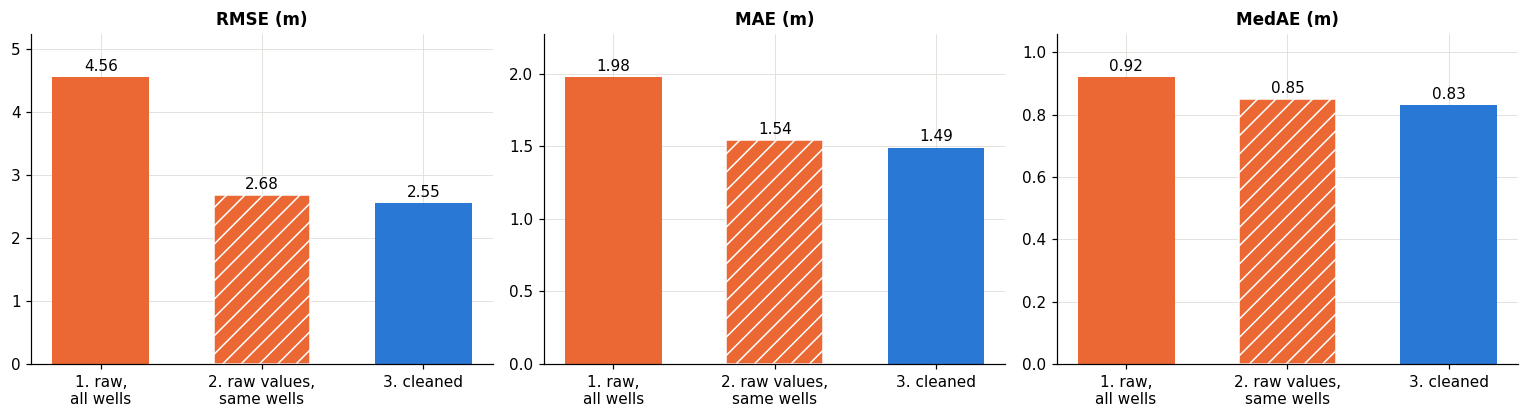

In [16]:
rule = em.PRIMARY_RULE
stages = [("1. raw table, all wells", raw_all, t_all), ("2. raw values, same 2,759 wells", raw_same, t_same),
          ("3. cleaned, 2,759 wells", ds, t_after)]
rows = []
for name, d, t in stages:
    x = t.set_index("rule").loc[rule]
    rows.append({"stage": name, "wells": len(d.values), "n": int(x.n), "RMSE": x.RMSE, "MAE": x.MAE, "MedAE": x.MedAE, "R2": x.R2})
dec = pd.DataFrame(rows).set_index("stage")
display(Markdown(f"### Rule: {rule}"))
display(Markdown("Step 1 → 2 changes **which wells** are scored: the authors kept only wells without negative values, with at least 2 readings in every year "
                 "and no stuck repeated values. Step 2 → 3 changes **values** only: outlier readings were blanked."))
display(dec.round(3))
sel = 100 * (dec.RMSE.iloc[0] - dec.RMSE.iloc[1]) / (dec.RMSE.iloc[0] - dec.RMSE.iloc[2])
selm = 100 * (dec.MAE.iloc[0] - dec.MAE.iloc[1]) / (dec.MAE.iloc[0] - dec.MAE.iloc[2])
display(Markdown(f"Share of the total reduction going from step 1 to step 3: RMSE **{sel:.1f}% from well selection** and {100 - sel:.1f}% from blanking readings; "
                 f"MAE {selm:.1f}% / {100 - selm:.1f}%. (R² is not comparable between stage 1 and the others; see the reading notes.)"))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for a, m in zip(ax, ["RMSE", "MAE", "MedAE"]):
    b = a.bar(range(3), dec[m], color=[BEFORE, BEFORE, AFTER], width=0.6)
    b[1].set_hatch("//"); b[1].set_edgecolor("white")
    a.bar_label(b, fmt="%.2f", padding=2)
    a.set_xticks(range(3), ["1. raw,\nall wells", "2. raw values,\nsame wells", "3. cleaned"])
    a.set_title(f"{m} (m)"); a.margins(y=0.15)
plt.tight_layout(); plt.show()

## 7. Save the results and summarise

In [17]:
results = t_after.copy()
results.to_csv(OUT / "error_metrics_after.csv", index=False)
pd.concat([em.breakdown(ds, r, "season").assign(data=ds.name, rule=r) for r in em.RULES], ignore_index=True) \
  .to_csv(OUT / "error_metrics_after_by_season.csv", index=False)
cmp_rows = []
for tag, tb in [("A: same 2,759 wells", t_same), ("B: all raw wells", t_all)]:
    for rule in em.RULES:
        sbs = side_by_side(tb, t_after, rule).reset_index().assign(comparison=tag, rule=rule)
        cmp_rows.append(sbs)
pd.concat(cmp_rows, ignore_index=True).to_csv(OUT / "error_metrics_comparison.csv", index=False)
print("saved:", OUT / "error_metrics_after.csv"); print("saved:", OUT / "error_metrics_after_by_season.csv")
print("saved:", OUT / "error_metrics_comparison.csv")

saved: /home/user/bde-team7/reports/tables/error_metrics_after.csv
saved: /home/user/bde-team7/reports/tables/error_metrics_after_by_season.csv
saved: /home/user/bde-team7/reports/tables/error_metrics_comparison.csv


In [18]:
shift = np.nanmean(ds.values[:, em.TEST_FIRST_COL:]) - np.nanmean(ds.values[:, :em.TEST_FIRST_COL])
cmp = side_by_side(t_same, t_after, em.PRIMARY_RULE)
better = int((cmp.verdict == "better").sum())
display(Markdown(f'''
## Scorecard: did preprocessing help? (same 2,759 wells, rule: {em.PRIMARY_RULE}, test period 2018–2022)

**{better} of {len(cmp)} metrics improved** after cleaning.

- RMSE {cmp.loc["RMSE (m)", "before"]:.3f} → **{cmp.loc["RMSE (m)", "after"]:.3f} m** ({cmp.loc["RMSE (m)", "improvement"]:+.1f}%); MSE {cmp.loc["MSE (m²)", "improvement"]:+.1f}%
- MAE {cmp.loc["MAE (m)", "before"]:.3f} → **{cmp.loc["MAE (m)", "after"]:.3f} m** ({cmp.loc["MAE (m)", "improvement"]:+.1f}%); MedAE {cmp.loc["MedAE (m)", "improvement"]:+.1f}%
- R² {cmp.loc["R2", "before"]:.3f} → **{cmp.loc["R2", "after"]:.3f}** ({cmp.loc["R2", "change"]:+.3f})
- MAPE {cmp.loc["MAPE (%)", "before"]:.1f}% → **{cmp.loc["MAPE (%)", "after"]:.1f}%**; NRMSE {cmp.loc["NRMSE (fraction of range)", "before"]:.3f} → **{cmp.loc["NRMSE (fraction of range)", "after"]:.3f}**
- |Bias| {abs(cmp.loc["Bias (m)", "before"]):.3f} → {abs(cmp.loc["Bias (m)", "after"]):.3f} m (the test period is {abs(shift):.2f} m {"shallower" if shift < 0 else "deeper"} on average than the earlier years the rules learn from, consistent with the {"positive" if cmp.loc["Bias (m)", "after"] > 0 else "negative"} bias)

**Why the improvement is modest:** the cleaning only blanked {blanked:,} extreme readings ({100 * blanked / np.isfinite(raw_same.values).sum():.2f}% of the readings) and changed no other value.
Across the whole raw table the bigger gain ({sel:.0f}% of the RMSE reduction) comes from *which wells were kept* (the authors' selection rules), not from fixing values.
This pipeline's own steps add flags and features and change no reading, so on their own they would score identically to the raw values.
'''))


## Scorecard: did preprocessing help? (same 2,759 wells, rule: same season last year, test period 2018–2022)

**8 of 8 metrics improved** after cleaning.

- RMSE 2.684 → **2.554 m** (+4.8%); MSE +9.4%
- MAE 1.542 → **1.491 m** (+3.3%); MedAE +2.4%
- R² 0.689 → **0.712** (+0.023)
- MAPE 37.8% → **36.8%**; NRMSE 0.040 → **0.038**
- |Bias| 0.210 → 0.209 m (the test period is 0.51 m shallower on average than the earlier years the rules learn from, consistent with the positive bias)

**Why the improvement is modest:** the cleaning only blanked 1,217 extreme readings (0.55% of the readings) and changed no other value.
Across the whole raw table the bigger gain (94% of the RMSE reduction) comes from *which wells were kept* (the authors' selection rules), not from fixing values.
This pipeline's own steps add flags and features and change no reading, so on their own they would score identically to the raw values.
